# Block 2 Checkpoint: Colliding Spring-Connected Masses

**Name:** Alex Bebb  
**Course:** PHYS 311  
**Date:** October 18, 2026  

I will use my Lab 7 engine to model four equal masses connected by
springs and falling under uniform gravity. The outer masses will
initially move inward, producing collisions as the chain compresses.

The model will combine spring forces, gravity, and frictionless
elastic collisions. I will check mechanical energy, horizontal
momentum, and the expected vertical momentum change, then repeat
the simulation with a smaller time step.

I will include figures showing the motion and the validation results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from lab07_engine.body import Body
from lab07_engine.forces import Gravity, Spring
from lab07_engine.integrators import VelocityVerlet
from lab07_engine.collisions import CircleCollisions
from lab07_engine.world import World

print("Engine imported successfully.")

Engine imported successfully.


## Scene and physical assumptions

I will model four 1 kg circular bodies, each with radius 0.2 m.
Three springs will connect neighboring bodies, with spring constant
2 N/m and rest length 1 m.

All four bodies will begin at a height of 5 m. The outer bodies
will move inward at 2 m/s, while the inner bodies will initially
be at rest. Uniform gravity will act downward with g = 1 m/s².

The bodies will undergo frictionless elastic collisions. There
will be no ground or walls during the two-second simulation.

The springs and collision impulses are internal interactions,
so total horizontal momentum should remain constant. Vertical
momentum should change according to the gravitational impulse:

$$
P_y(t)=P_y(0)-Mgt.
$$

Mechanical energy includes kinetic energy, gravitational potential
energy, and spring potential energy. It should be conserved in
the ideal model. Numerical overlap corrections can change spring
potential energy slightly, so I will check time-step sensitivity.

In [2]:
def run_checkpoint(dt):
    """Run four spring-connected bodies with gravity and elastic collisions."""
    world = World(integrator=VelocityVerlet())

    initial_x = [-1.5, -0.5, 0.5, 1.5]
    initial_vx = [2.0, 0.0, 0.0, -2.0]

    for i in range(4):
        world.add_body(
            Body(
                mass=1.0,
                position=[initial_x[i], 5.0],
                velocity=[initial_vx[i], 0.0],
                radius=0.2,
                name=f"body {i + 1}"
            )
        )

    world.add_force(Gravity(g=1.0))

    for i in range(3):
        world.add_force(
            Spring(
                index_a=i,
                index_b=i + 1,
                k=2.0,
                rest_length=1.0
            )
        )

    contacts = world.add_collision(
        CircleCollisions(restitution=1.0)
    )

    history = world.run(dt=dt, duration=2.0)

    return history, contacts.count


checkpoint_dt = 0.001
checkpoint_history, checkpoint_collision_count = run_checkpoint(checkpoint_dt)

checkpoint_time = checkpoint_history["time"]
checkpoint_position = checkpoint_history["position"]
checkpoint_energy = checkpoint_history["energy"]
checkpoint_momentum = checkpoint_history["momentum"]

print(f"Moving bodies: {checkpoint_position.shape[1]}")
print("Force types: Gravity and Spring")
print(f"Simulation duration: {checkpoint_time[-1]:.3f} s")
print(f"Stored time points: {len(checkpoint_time)}")
print(f"Collision impulses applied: {checkpoint_collision_count}")
print(f"Initial mechanical energy: {checkpoint_energy[0]:.6f} J")
print(f"Final mechanical energy: {checkpoint_energy[-1]:.6f} J")

Moving bodies: 4
Force types: Gravity and Spring
Simulation duration: 2.000 s
Stored time points: 2001
Collision impulses applied: 5
Initial mechanical energy: 24.000000 J
Final mechanical energy: 23.994564 J


## Conservation-law validation

I will compare the recorded momentum with its physical prediction.
The total mass is 4 kg, and the initial total momentum is zero:

$$
P_x(t)=0,
\qquad
P_y(t)=-4t.
$$

I will also plot the relative change in mechanical energy. A small
energy error is expected from the finite time step and contact
position corrections, even though the modeled collisions are elastic.

The momentum checks and energy check test different aspects of the
engine. Correct momentum alone does not guarantee correct energy.

Maximum horizontal momentum error: 2.220e-16 kg m/s
Maximum vertical momentum error: 2.216e-13 kg m/s
Maximum energy deviation: 5.436680e-03 J
Maximum relative energy deviation: 0.022653%


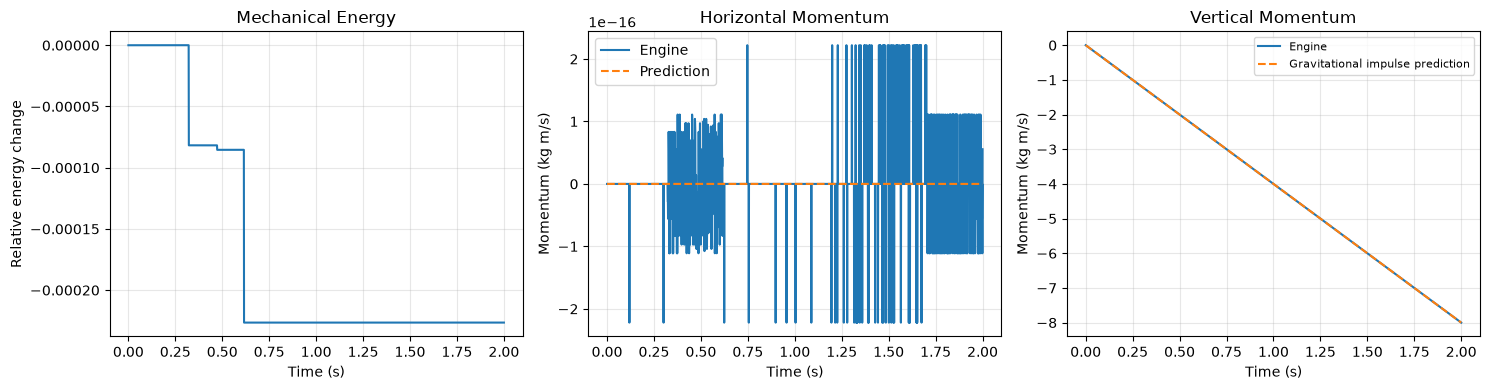

In [3]:
expected_px = np.zeros_like(checkpoint_time)
expected_py = -4.0 * checkpoint_time

px_error = np.max(
    np.abs(checkpoint_momentum[:, 0] - expected_px)
)
py_error = np.max(
    np.abs(checkpoint_momentum[:, 1] - expected_py)
)

checkpoint_energy_error = np.max(
    np.abs(checkpoint_energy - checkpoint_energy[0])
)
checkpoint_relative_energy_error = (
    checkpoint_energy_error / abs(checkpoint_energy[0])
)

print(f"Maximum horizontal momentum error: {px_error:.3e} kg m/s")
print(f"Maximum vertical momentum error: {py_error:.3e} kg m/s")
print(f"Maximum energy deviation: {checkpoint_energy_error:.6e} J")
print(
    f"Maximum relative energy deviation: "
    f"{100 * checkpoint_relative_energy_error:.6f}%"
)

fig_validation, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    checkpoint_time,
    (checkpoint_energy - checkpoint_energy[0]) / abs(checkpoint_energy[0])
)
axes[0].set_title("Mechanical Energy")
axes[0].set_ylabel("Relative energy change")

axes[1].plot(
    checkpoint_time, checkpoint_momentum[:, 0],
    label="Engine"
)
axes[1].plot(
    checkpoint_time, expected_px,
    "--", label="Prediction"
)
axes[1].set_title("Horizontal Momentum")
axes[1].set_ylabel("Momentum (kg m/s)")
axes[1].legend()

axes[2].plot(
    checkpoint_time, checkpoint_momentum[:, 1],
    label="Engine"
)
axes[2].plot(
    checkpoint_time, expected_py,
    "--", label="Gravitational impulse prediction"
)
axes[2].set_title("Vertical Momentum")
axes[2].set_ylabel("Momentum (kg m/s)")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("Time (s)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Time-step refinement

I will repeat the scene with smaller time steps and compare the
maximum mechanical energy deviations and collision counts.

Although Velocity Verlet is second order for smooth motion,
collision detection and overlap correction introduce additional
errors. I will therefore measure the improvement rather than assume
that halving the time step must reduce the error by exactly four.

The refinement check will help distinguish numerical energy changes
from physical dissipation. The modeled collisions are elastic, so
physical dissipation is not expected.

In [4]:
checkpoint_refinement = []

for dt in [0.002, 0.001, 0.0005]:
    history, collision_count = run_checkpoint(dt)

    energy = history["energy"]
    maximum_error = np.max(np.abs(energy - energy[0]))
    percentage_error = 100 * maximum_error / abs(energy[0])

    checkpoint_refinement.append(
        (dt, collision_count, maximum_error, percentage_error)
    )

print(
    f"{'dt (s)':>10} {'Collisions':>12}"
    f" {'Max energy error (J)':>23} {'Error (%)':>14}"
)

for dt, count, error, percentage in checkpoint_refinement:
    print(
        f"{dt:>10.6f} {count:>12}"
        f" {error:>23.6e} {percentage:>14.6f}"
    )

    dt (s)   Collisions    Max energy error (J)      Error (%)
  0.002000            5            1.102367e-02       0.045932
  0.001000            5            5.436680e-03       0.022653
  0.000500            5            8.950658e-04       0.003729


## Figure sequence: compression, collisions, and falling motion

I will show six snapshots of the scene using consistent axis limits
and equal horizontal and vertical scales. The circles will show the
actual collision radii, and lines will show the spring connections.

Arrows will indicate horizontal velocity so the collision-driven
changes in motion are easier to follow. Vertical velocity is omitted
from the arrows because all bodies share the same falling motion.

The sequence will show the initially inward-moving outer bodies,
compression and collision interactions, and the later configuration.
Together with the validation panel, it will serve as the visual
walkthrough of the demo.

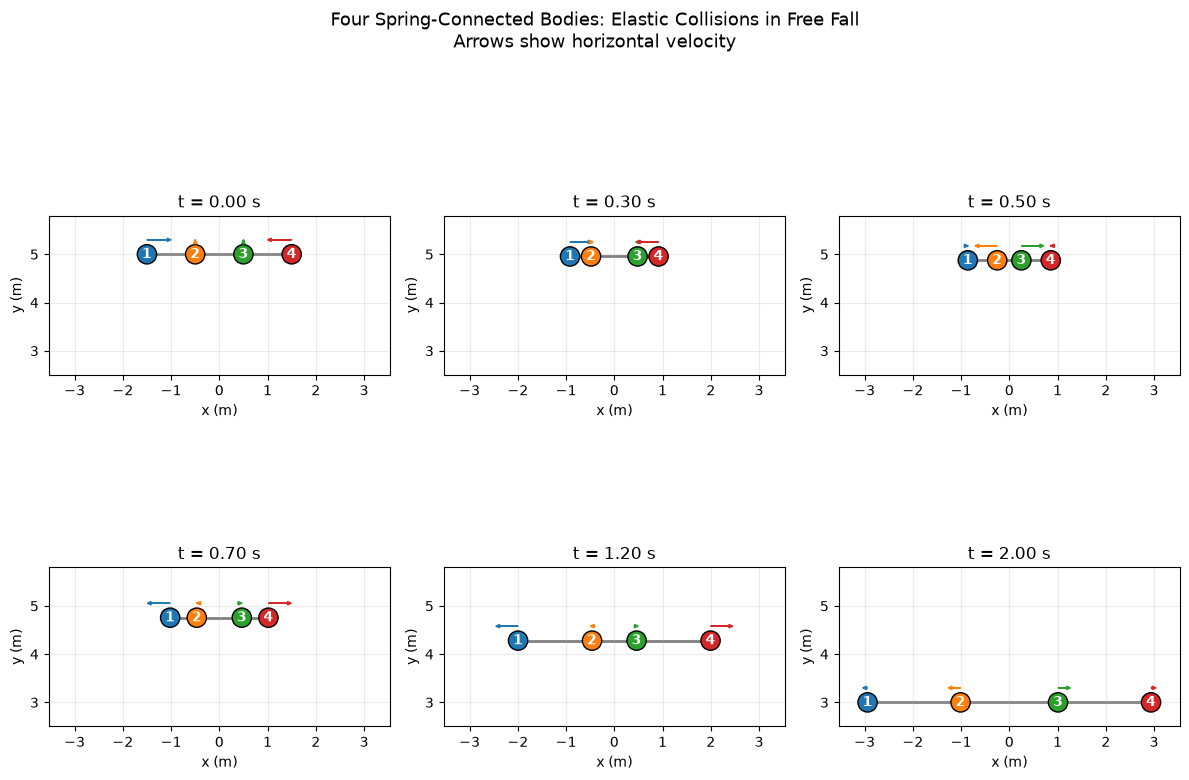

In [5]:
snapshot_times = [0.0, 0.3, 0.5, 0.7, 1.2, 2.0]
body_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

fig_sequence, axes = plt.subplots(2, 3, figsize=(12, 9))

for ax, requested_time in zip(axes.flat, snapshot_times):
    index = np.argmin(np.abs(checkpoint_time - requested_time))

    positions = checkpoint_position[index]
    velocities = checkpoint_history["velocity"][index]

    # Draw the three springs.
    ax.plot(
        positions[:, 0], positions[:, 1],
        color="gray", linewidth=2, zorder=1
    )

    for body_index, color in enumerate(body_colors):
        x, y = positions[body_index]

        circle = Circle(
            (x, y),
            radius=0.2,
            facecolor=color,
            edgecolor="black",
            zorder=3
        )
        ax.add_patch(circle)

        ax.text(
            x, y, str(body_index + 1),
            ha="center", va="center",
            color="white", weight="bold", zorder=4
        )

        # Arrow length is scaled from horizontal velocity.
        ax.arrow(
            x, y + 0.3,
            0.25 * velocities[body_index, 0], 0.0,
            head_width=0.07,
            head_length=0.08,
            length_includes_head=True,
            color=color,
            zorder=4
        )

    ax.set_xlim(
        checkpoint_position[:, :, 0].min() - 0.6,
        checkpoint_position[:, :, 0].max() + 0.6
    )
    ax.set_ylim(2.5, 5.8)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(f"t = {checkpoint_time[index]:.2f} s")
    ax.grid(True, alpha=0.25)

fig_sequence.suptitle(
    "Four Spring-Connected Bodies: Elastic Collisions in Free Fall\n"
    "Arrows show horizontal velocity",
    fontsize=13
)
plt.tight_layout()
plt.show()

## Interpretation

The four bodies interacted through springs and elastic collisions while
falling under gravity. The snapshots show the bodies exchanging horizontal
motion while falling together vertically. The simulation recorded five
collision impulses.

Horizontal momentum stayed constant to within floating-point roundoff.
Vertical momentum changed because gravity exerted an external force on
the system, and the numerical result agreed closely with the predicted
change of -Mgt.

The collisions were modeled as elastic, so the total mechanical energy
should remain constant when gravitational and spring potential energy
are included. The simulation had a small energy error. Reducing the time
step reduced the maximum energy error, which supports the numerical
result. The collision routine corrects overlapping positions, so it can
introduce energy errors even when the collision impulse itself conserves
kinetic energy.

This scene reused the existing engine by adding bodies, forces, and a
collision handler to a World. It did not require a new time-stepping loop.
The model assumes ideal springs and frictionless circular bodies, without
air resistance or rotational effects from collisions.

## Saving the checkpoint figures and README

The next cell saves the snapshot sequence and conservation plots as PNG
images. The snapshot sequence provides a visual walkthrough of the scene.

It also creates a README describing the engine architecture, the physical
model, and how to run the notebook. These files are saved in a checkpoints
folder beside this notebook.

In [6]:
from pathlib import Path

# Create the output folder if it does not already exist.
output_folder = Path("checkpoints")
output_folder.mkdir(exist_ok=True)

# Save the existing figures.
fig_sequence.savefig(
    output_folder / "block02_sequence.png",
    dpi=180,
    bbox_inches="tight"
)

fig_validation.savefig(
    output_folder / "block02_validation.png",
    dpi=180,
    bbox_inches="tight"
)

# Describe the project and how to reproduce its results.
readme_text = """# Block 2 Checkpoint: Colliding Spring-Connected Masses

## Overview
Four equal-mass circular bodies interact through three springs and
frictionless elastic collisions while falling under uniform gravity.
The scene uses the reusable Lab 7 physics engine.

## Required software
Python 3, Jupyter Notebook or JupyterLab, NumPy, and Matplotlib.

## File layout
Keep block02_checkpoint.ipynb beside the lab07_engine folder.
The checkpoints folder contains this README and the exported figures.

## How to run
Open block02_checkpoint.ipynb in Jupyter.
Choose Restart Kernel and Run All Cells.
Run from the folder containing the notebook and lab07_engine.
The final code cell regenerates the figures and this README.

## Engine architecture
- Body stores each body's physical properties and current state.
- Force objects calculate forces and potential energy.
- VelocityVerlet advances positions and velocities.
- CircleCollisions handles contact impulses and overlap correction.
- World combines the components, advances time, and records results.

The notebook configures the scene and analyzes recorded data.
Time stepping takes place inside the engine.

## Physical model
- Four bodies, each with mass 1 kg and radius 0.2 m.
- Three springs, each with stiffness 2 N/m and rest length 1 m.
- Uniform gravitational acceleration of 1 m/s^2 downward.
- Elastic collisions with coefficient of restitution 1.
- Simulation duration of 2 s and main time step of 0.001 s.
- No walls, ground, air resistance, or contact friction.

## Validation
Horizontal momentum should remain constant.
Vertical momentum should follow Py(t) = -M*g*t because initial
vertical momentum is zero.
Total mechanical energy includes kinetic, gravitational potential,
and spring potential energy.

The notebook checks these quantities and compares energy errors
at time steps of 0.002, 0.001, and 0.0005 s.
The collision overlap corrections can introduce numerical energy error.

## Visual walkthrough
block02_sequence.png shows six snapshots of the motion.
Colors and numbers identify the bodies, connecting lines represent
springs, and arrows indicate horizontal velocity.
block02_validation.png shows the energy and momentum checks.

## Limitations
Collisions are detected at discrete time steps, so choosing a sufficiently
small time step matters. The model uses ideal springs and frictionless
contacts and does not model collision-induced rotation.
"""

readme_path = output_folder / "README_block02.md"
readme_path.write_text(readme_text, encoding="utf-8")

print("Saved checkpoint files:")
for filename in (
    "block02_sequence.png",
    "block02_validation.png",
    "README_block02.md",
):
    print(output_folder / filename)

Saved checkpoint files:
checkpoints\block02_sequence.png
checkpoints\block02_validation.png
checkpoints\README_block02.md
